# Part 2: fine-tuning ResNet-18 on FGVC-Aircraft


## Scope and result status

The implementation uses torchvision's ResNet-18 with ResNet18_Weights.IMAGENET1K_V1 and replaces its 512-to-1000 classifier with a 512-to-100 linear layer. Every experiment starts from ImageNet weights and the same random seed.

**New full-dataset training has not been run.** The local environment has PyTorch 2.13.0+cpu, torchvision 0.28.0+cpu, approximately 8 GB RAM, and no CUDA device. Functional checks passed using the actual pretrained model and small synthetic fixtures; these checks do not establish aircraft accuracy.

The original notebook at repository commit a27f7ed contains a saved 50-epoch baseline accuracy trace. Its best recorded test accuracy is **84.31% at epoch 50**, above the assignment's approximate 70% target. The original markdown table instead gives 83.98% at epoch 42, which does not match that trace. This report uses the trace when discussing baseline behavior.

The original table also reports **87.13% for Model 3**, but its complete epoch outputs and trained checkpoint are absent from this repository. This is an existing, unverified claim, not a newly measured result. The corrected implementation needs a full run before a new Part 2B improvement can be claimed.

## How to run

This notebook is self-contained and can be uploaded directly to Colab.
Its saved outputs show analysis and setup, not a new training run.

1. Select a GPU runtime, if available.
2. In the **Run Part 2A and Part 2B** cell near the end, set RUN_FULL_TRAINING = True.
3. Run all cells. The dataset downloads through torchvision.
4. Keep OUTPUT_DIR on persistent storage if the runtime can disconnect.

The default False setting lets you inspect existing evidence without launching
a long training job. CPU execution is supported but may take many hours.
Reusing OUTPUT_DIR resumes interrupted experiments.

In [1]:
import argparse
import csv
import hashlib
import json
import math
import random
import time
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models import ResNet18_Weights, resnet18

NUM_CLASSES = 100
WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


@dataclass(frozen=True)
class Config:
    name: str
    seed: int = 42
    batch_size: int = 32
    head_epochs: int = 0
    full_epochs: int = 50
    head_lr: float = 1e-3
    full_lr: float = 3e-4
    weight_decay: float = 1e-4
    label_smoothing: float = 0.1
    schedule: str = "constant"

    def __post_init__(self):
        if self.full_epochs < 1 or self.head_epochs < 0 or self.batch_size < 1:
            raise ValueError("Invalid epoch count or batch size.")
        if self.schedule not in {"constant", "warmup_cosine"}:
            raise ValueError("Unknown schedule.")
        if self.schedule == "warmup_cosine":
            if self.full_epochs < 3 or (self.head_epochs and self.head_epochs < 3):
                raise ValueError("Warm-up/cosine stages need at least three epochs.")

    @property
    def total_epochs(self):
        return self.head_epochs + self.full_epochs


BASELINE = Config(name="2A_baseline")
CANDIDATES = [
    Config(name="2B_lr_1e-3", head_epochs=5, full_epochs=35,
           full_lr=1e-3, schedule="warmup_cosine"),
    Config(name="2B_lr_3e-4", head_epochs=5, full_epochs=35,
           full_lr=3e-4, schedule="warmup_cosine"),
]


def seed_everything(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

In [2]:
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
print("Required weights:", WEIGHTS)
print("Part 2A:", asdict(BASELINE))

PyTorch: 2.13.0+cpu
torchvision: 0.28.0+cpu
Device: cpu
Required weights: ResNet18_Weights.IMAGENET1K_V1
Part 2A: {'name': '2A_baseline', 'seed': 42, 'batch_size': 32, 'head_epochs': 0, 'full_epochs': 50, 'head_lr': 0.001, 'full_lr': 0.0003, 'weight_decay': 0.0001, 'label_smoothing': 0.1, 'schedule': 'constant'}


## Part 2A: preserve the recorded Part 1 settings

Part 1 is not present in the repository. The user confirmed using the baseline settings recorded in the original notebook.

| Setting | Part 2A |
|---|---|
| Initialization | ResNet-18, ImageNet-1K V1 |
| Trainable parameters | Entire network, from epoch 1 |
| Training split | Official trainval (6,667 images) |
| Final evaluation split | Official test (3,333 images) |
| Epochs / batch size | 50 / 32 |
| Optimizer | AdamW, default betas (0.9, 0.999), epsilon 1e-8 |
| Learning rate | Constant 3e-4 |
| Weight decay | 1e-4 |
| Loss | Cross-entropy, label smoothing 0.1 |
| Preprocessing | Remove bottom 20 pixels; resize to 224 x 336 |
| Augmentation | Horizontal flip 0.5; rotation +/-5 degrees; color jitter 0.1 |
| Erasing | Probability 0.1, area 0.02-0.04, ratio 0.5-2.0, before normalization |
| Normalization | Mean (0.485, 0.456, 0.406), std (0.229, 0.224, 0.225) |
| Random seed / precision | 42 / float32 |

Footer removal follows the [dataset authors' instructions](https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/). Resizing to a fixed height and width changes the original aspect ratio; it matches the recorded baseline. ImageNet normalization matches the [V1 weights documentation](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html).

Part 2A trains for the fixed 50-epoch budget and evaluates that final model. It does not select a checkpoint using test accuracy. This keeps the requested training hyperparameters and training split while correcting the original test-based selection.

## What the saved baseline curve supports



This plot is reconstructed from the original notebook's saved text output in zero-based cell 23, not from a new run. All 50 rounded observations are included in reports/baseline_recorded_accuracy.csv.

- Epoch 4 already reaches 73.03% test accuracy.
- At epoch 10, training accuracy is 98.13%, while test accuracy is 76.27%.
- At epoch 50, training accuracy is 99.96% and test accuracy is 84.31%, a gap of 15.65 percentage points.
- Late test accuracy fluctuates, including a drop to 72.85% at epoch 46.

The gap is consistent with limited generalization and possible overfitting. Saturated training accuracy does **not** rule out overfitting. Fluctuations motivate trying a decaying learning rate, but they do not prove that the constant rate caused them. A noisy trajectory also cannot establish that a model is near a global optimum. Training accuracy is measured on augmented batches during updates, while evaluation uses deterministic images; the curves are not measured under identical conditions.

The existing test curves have already been inspected and used to compare models. They are exploratory evidence, not an untouched estimate of generalization.

Saved baseline maximum: 84.31% (epoch 50).
Legacy tuned claim: 87.13%; complete supporting training output is absent.


Fallback to a different backend


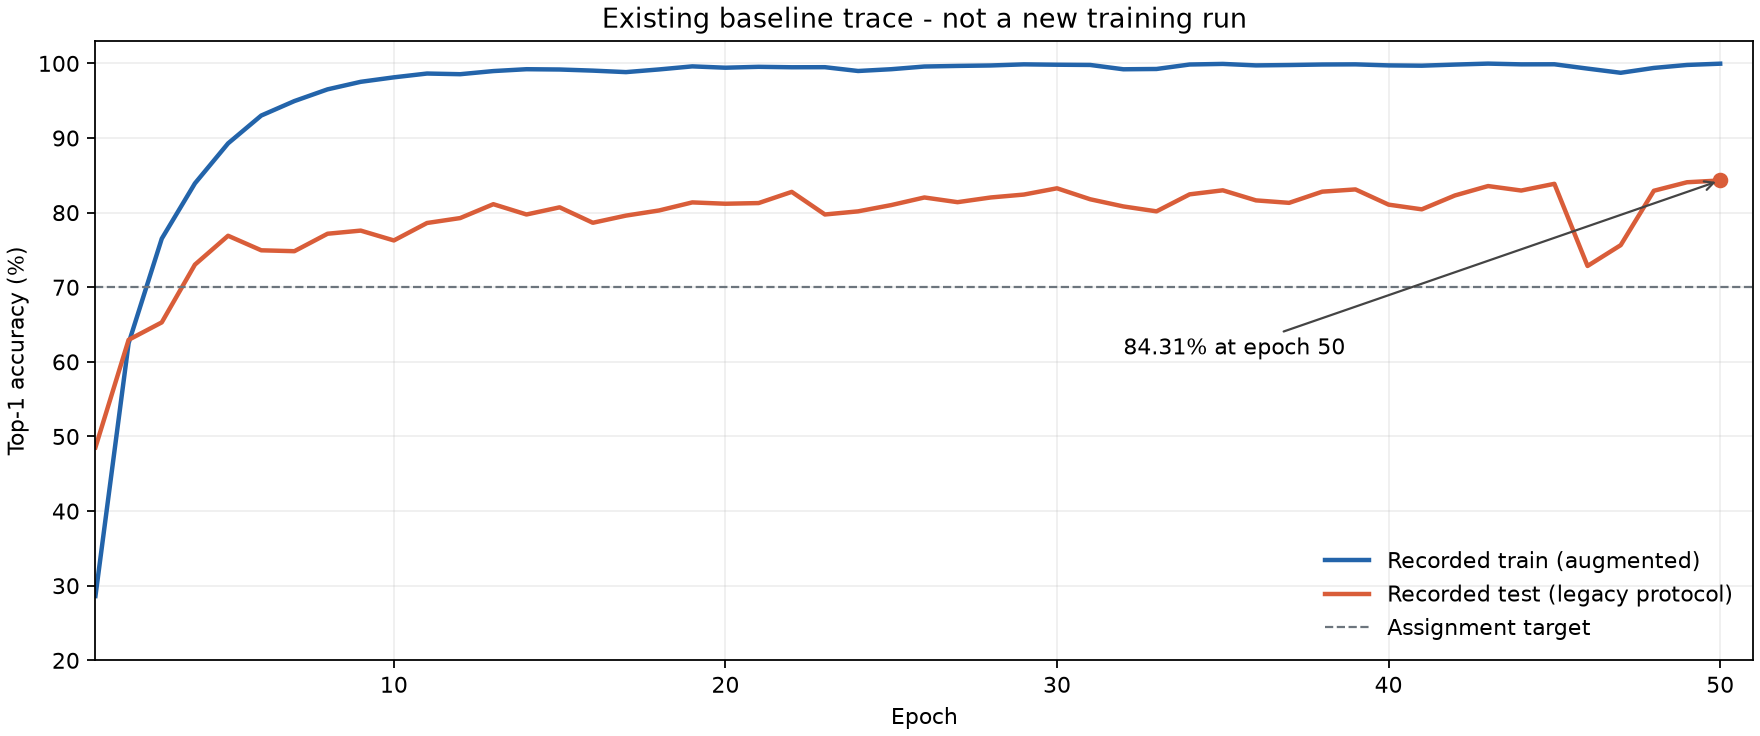

In [3]:
RECORDED_BASELINE = [{'epoch': 1, 'train_accuracy': 0.2862, 'test_accuracy': 0.4854}, {'epoch': 2, 'train_accuracy': 0.625, 'test_accuracy': 0.6295}, {'epoch': 3, 'train_accuracy': 0.7651, 'test_accuracy': 0.6529}, {'epoch': 4, 'train_accuracy': 0.8392, 'test_accuracy': 0.7303}, {'epoch': 5, 'train_accuracy': 0.8928, 'test_accuracy': 0.769}, {'epoch': 6, 'train_accuracy': 0.9301, 'test_accuracy': 0.7495}, {'epoch': 7, 'train_accuracy': 0.9495, 'test_accuracy': 0.7483}, {'epoch': 8, 'train_accuracy': 0.9652, 'test_accuracy': 0.7717}, {'epoch': 9, 'train_accuracy': 0.9753, 'test_accuracy': 0.7759}, {'epoch': 10, 'train_accuracy': 0.9813, 'test_accuracy': 0.7627}, {'epoch': 11, 'train_accuracy': 0.9864, 'test_accuracy': 0.7861}, {'epoch': 12, 'train_accuracy': 0.9855, 'test_accuracy': 0.7927}, {'epoch': 13, 'train_accuracy': 0.9897, 'test_accuracy': 0.8113}, {'epoch': 14, 'train_accuracy': 0.9922, 'test_accuracy': 0.7975}, {'epoch': 15, 'train_accuracy': 0.9918, 'test_accuracy': 0.8071}, {'epoch': 16, 'train_accuracy': 0.9903, 'test_accuracy': 0.7864}, {'epoch': 17, 'train_accuracy': 0.9883, 'test_accuracy': 0.796}, {'epoch': 18, 'train_accuracy': 0.9919, 'test_accuracy': 0.8029}, {'epoch': 19, 'train_accuracy': 0.996, 'test_accuracy': 0.8137}, {'epoch': 20, 'train_accuracy': 0.9942, 'test_accuracy': 0.8119}, {'epoch': 21, 'train_accuracy': 0.9954, 'test_accuracy': 0.8128}, {'epoch': 22, 'train_accuracy': 0.9948, 'test_accuracy': 0.8278}, {'epoch': 23, 'train_accuracy': 0.9949, 'test_accuracy': 0.7975}, {'epoch': 24, 'train_accuracy': 0.9898, 'test_accuracy': 0.8017}, {'epoch': 25, 'train_accuracy': 0.9922, 'test_accuracy': 0.8101}, {'epoch': 26, 'train_accuracy': 0.9958, 'test_accuracy': 0.8203}, {'epoch': 27, 'train_accuracy': 0.9966, 'test_accuracy': 0.814}, {'epoch': 28, 'train_accuracy': 0.9972, 'test_accuracy': 0.8203}, {'epoch': 29, 'train_accuracy': 0.9987, 'test_accuracy': 0.8242}, {'epoch': 30, 'train_accuracy': 0.9982, 'test_accuracy': 0.8326}, {'epoch': 31, 'train_accuracy': 0.9979, 'test_accuracy': 0.8179}, {'epoch': 32, 'train_accuracy': 0.9921, 'test_accuracy': 0.8083}, {'epoch': 33, 'train_accuracy': 0.9925, 'test_accuracy': 0.8017}, {'epoch': 34, 'train_accuracy': 0.9985, 'test_accuracy': 0.8245}, {'epoch': 35, 'train_accuracy': 0.9993, 'test_accuracy': 0.8299}, {'epoch': 36, 'train_accuracy': 0.9973, 'test_accuracy': 0.8164}, {'epoch': 37, 'train_accuracy': 0.9978, 'test_accuracy': 0.8131}, {'epoch': 38, 'train_accuracy': 0.9985, 'test_accuracy': 0.8281}, {'epoch': 39, 'train_accuracy': 0.9987, 'test_accuracy': 0.8311}, {'epoch': 40, 'train_accuracy': 0.9973, 'test_accuracy': 0.8107}, {'epoch': 41, 'train_accuracy': 0.9969, 'test_accuracy': 0.8044}, {'epoch': 42, 'train_accuracy': 0.9984, 'test_accuracy': 0.823}, {'epoch': 43, 'train_accuracy': 0.9997, 'test_accuracy': 0.8356}, {'epoch': 44, 'train_accuracy': 0.9987, 'test_accuracy': 0.8296}, {'epoch': 45, 'train_accuracy': 0.9988, 'test_accuracy': 0.8386}, {'epoch': 46, 'train_accuracy': 0.993, 'test_accuracy': 0.7285}, {'epoch': 47, 'train_accuracy': 0.9874, 'test_accuracy': 0.7564}, {'epoch': 48, 'train_accuracy': 0.9939, 'test_accuracy': 0.8293}, {'epoch': 49, 'train_accuracy': 0.9979, 'test_accuracy': 0.8407}, {'epoch': 50, 'train_accuracy': 0.9996, 'test_accuracy': 0.8431}]

# Saved observations from the original notebook, not generated scores.
from IPython.display import Image, Markdown, display
REPORT_DIR = Path("reports")
REPORT_DIR.mkdir(exist_ok=True)
epochs = [row["epoch"] for row in RECORDED_BASELINE]
fig, ax = plt.subplots(figsize=(11, 4.6), constrained_layout=True)
ax.plot(epochs, [100 * row["train_accuracy"] for row in RECORDED_BASELINE],
        color="#2364AA", linewidth=2, label="Recorded train (augmented)")
ax.plot(epochs, [100 * row["test_accuracy"] for row in RECORDED_BASELINE],
        color="#D95D39", linewidth=2, label="Recorded test (legacy protocol)")
ax.axhline(70, color="#6C757D", linestyle="--", linewidth=1, label="Assignment target")
ax.scatter([50], [84.31], color="#D95D39", zorder=3)
ax.annotate("84.31% at epoch 50", xy=(50, 84.31), xytext=(32, 61),
            arrowprops={"arrowstyle": "->", "color": "#444444"}, fontsize=10)
ax.set(xlabel="Epoch", ylabel="Top-1 accuracy (%)", ylim=(20, 103), xlim=(1, 51),
       title="Existing baseline trace - not a new training run")
ax.grid(alpha=0.2)
ax.legend(loc="lower right", frameon=False)
fig.savefig(REPORT_DIR / "baseline_recorded_accuracy.png", dpi=160)
plt.close(fig)
display(Image(filename=str(REPORT_DIR / "baseline_recorded_accuracy.png")))
best = max(RECORDED_BASELINE, key=lambda row: row["test_accuracy"])
print(f"Saved baseline maximum: {100 * best['test_accuracy']:.2f}% (epoch {best['epoch']}).")
print("Legacy tuned claim: 87.13%; complete supporting training output is absent.")

## Part 2B: tuning choices and justification

The new implementation compares two compact candidates. All settings not listed below remain identical to Part 2A.

| Setting | Candidate B1 | Candidate B2 |
|---|---|---|
| Head-only training | 5 epochs | 5 epochs |
| Head peak learning rate | 1e-3 | 1e-3 |
| Full-network training | Up to 35 further epochs | Up to 35 further epochs |
| Full-network peak learning rate | 1e-3 | 3e-4 |
| Schedule | One low-LR warm-up epoch, then cosine decay | Same |
| Minimum LR, head / full | 1e-5 / 1e-7 | 1e-5 / 1e-7 |
| Tuning train / validation splits | Official train / val | Same |

**Train the classifier first, then adapt the whole network.** The classifier starts randomly initialized, whereas the backbone already contains visual features. Five head-only epochs give the classifier a useful starting point before all parameters are updated. The [PyTorch transfer-learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html) demonstrates both training a new classifier and fine-tuning pretrained weights. [Stanford CS231n](https://cs231n.github.io/transfer-learning/) explains why early and late features can transfer differently. These sources motivate the experiment; they do not establish that five epochs or a particular LR is optimal for aircraft.

**Freeze BatchNorm state during the head stage.** Freezing gradients alone leaves BatchNorm running statistics mutable under training mode. The implementation sets the backbone to evaluation mode for the head-only stage. Full fine-tuning restores training mode and gradient updates throughout the backbone. This fixes unintended changes in the original notebook.

**Try a larger peak rate, with a conservative comparator.** B1 explores more adaptation to fine-grained aircraft differences. B2 retains the baseline peak rate. The original table reports 87.13% and 86.44% for similar settings, respectively, but missing logs and shared state prevent treating those figures as verified evidence of a controlled comparison. The new runs use independent models, histories, optimizers, and checkpoint directories.

**Decay the learning rate.** A larger early rate permits substantial adaptation; a smaller late rate may reduce oscillation. Cosine annealing is motivated by [Loshchilov and Hutter, SGDR](https://arxiv.org/abs/1608.03983). This implementation uses one cosine decay in each stage, with AdamW and without restarts; it does not reproduce the whole SGDR method. Each stage begins with one epoch at 1% of its peak rate. The next epoch uses the peak, and the last configured epoch uses the minimum. This explicit epoch schedule avoids an off-by-one minimum applied only after training has ended. No linear within-epoch warm-up is claimed.

**Keep regularization and augmentation fixed.** Weight decay, label smoothing, and the existing mild augmentation remain unchanged. This narrows the comparison to optimization and training stages. These two candidates are not a full ablation: they cannot isolate every change relative to Part 2A. The original claim that augmentation caused high accuracy is a hypothesis; the original augmentation-ablation cells contain no saved results.

## Selection and final evaluation

1. Run Part 2A on trainval for exactly 50 epochs.
2. Train each Part 2B candidate on the official train split and evaluate each epoch on val. Select the best full-fine-tuning epoch by validation accuracy, with lower validation loss breaking ties.
3. Choose the candidate by its validation result. Reinitialize from ImageNet and refit on trainval for its selected number of epochs. Retain the original learning-rate schedule up to that epoch, rather than compressing the schedule.
4. Evaluate the fixed Part 2A and Part 2B models on the complete test split. Do not use that result to choose another checkpoint or candidate.

The API supports these official splits through [torchvision FGVCAircraft](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.FGVCAircraft.html). Validation-based checkpoint selection follows the PyTorch tutorial cited above. New validation runs use fewer training images than the final refit, so their accuracy is not directly comparable to the legacy trainval-to-test results.

Both final models use the same 6,667 training images. The workflow reports top-1 sample accuracy and mean per-class accuracy, the latter corresponding to the dataset's stated benchmark metric. It also saves the confusion matrix and per-image predictions. Smoothed loss is labeled separately from ordinary cross-entropy, since label smoothing changes the numerical scale of loss.

The summary and comparison files are populated only after a real full run. They state whether Part 2B reached 70% and whether it improved on Part 2A. If either criterion fails, report the failure; do not substitute an expected or historical accuracy.

## Implementation: Data, model, learning rate, and metrics

In [4]:
class CropCopyrightAndResize:
    """Remove the bottom 20 pixels, then resize to (height, width).

    A two-element resize fixes the aspect ratio; it does NOT preserve the
    original ratio. This intentionally matches the recorded Part 1 pipeline.
    """
    def __init__(self, size=(224, 336)):
        self.size = size

    def __call__(self, image):
        width, height = image.size
        if height <= 20:
            raise ValueError("Image is too short to remove the copyright banner.")
        image = image.crop((0, 0, width, height - 20))
        return transforms.functional.resize(image, self.size, antialias=True)


def make_transform(training):
    operations = [CropCopyrightAndResize()]
    if training:
        operations += [
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(5),
            transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
        ]
    operations += [transforms.ToTensor()]
    if training:
        operations += [transforms.RandomErasing(
            p=0.1, scale=(0.02, 0.04), ratio=(0.5, 2.0), value=0)]
    operations += [transforms.Normalize(MEAN, STD)]
    return transforms.Compose(operations)


def make_dataset(root, split, training, download=False):
    return torchvision.datasets.FGVCAircraft(
        root=str(root), split=split, annotation_level="variant",
        download=download, transform=make_transform(training))


def make_loader(dataset, config, training, device):
    # Zero workers works in Windows notebooks and makes epoch resumes reproducible.
    return DataLoader(
        dataset, batch_size=config.batch_size, shuffle=training, num_workers=0,
        pin_memory=device.type == "cuda", drop_last=False,
        generator=torch.Generator().manual_seed(config.seed))


def build_model(pretrained=True):
    model = resnet18(weights=WEIGHTS if pretrained else None)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model


def set_training_stage(model, head_only):
    for parameter in model.parameters():
        parameter.requires_grad_(not head_only)
    for parameter in model.fc.parameters():
        parameter.requires_grad_(True)
    if head_only:
        # requires_grad=False alone does not freeze BatchNorm running statistics.
        model.eval()
        model.fc.train()
    else:
        model.train()


def learning_rate(config, epoch):
    """Zero-based epoch. The LR used for the epoch is set before its updates."""
    head_only = epoch < config.head_epochs
    local_epoch = epoch if head_only else epoch - config.head_epochs
    count = config.head_epochs if head_only else config.full_epochs
    peak = config.head_lr if head_only else config.full_lr
    minimum = 1e-5 if head_only else 1e-7
    if config.schedule == "constant":
        return peak
    # One low-LR warm-up epoch, peak in the second, cosine to the final epoch.
    if local_epoch == 0:
        return 0.01 * peak
    progress = (local_epoch - 1) / (count - 2)
    return minimum + (peak - minimum) * (1 + math.cos(math.pi * progress)) / 2


def run_epoch(model, loader, device, criterion, optimizer=None, head_only=False):
    training = optimizer is not None
    if training:
        set_training_stage(model, head_only)
    else:
        model.eval()
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss; stop and inspect this run.")
            if training:
                loss.backward()
                optimizer.step()
            size = labels.size(0)
            total_loss += loss.item() * size
            correct += int((logits.argmax(1) == labels).sum())
            count += size
    if count == 0:
        raise ValueError("Cannot evaluate an empty loader.")
    return {"loss": total_loss / count, "accuracy": correct / count, "count": count}


def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")


def write_csv(path, rows):
    if not rows:
        return
    with Path(path).open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def atomic_save(value, path):
    path = Path(path)
    temporary = path.with_suffix(".tmp")
    torch.save(value, temporary)
    temporary.replace(path)


def plot_history(history, path, title):
    epochs = [row["epoch"] for row in history]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    for key, label, axis in [
        ("loss", "Cross-entropy (label smoothing = 0.1)", axes[0, 0]),
        ("accuracy", "Top-1 accuracy (%)", axes[0, 1]),
    ]:
        factor = 100 if key == "accuracy" else 1
        axis.plot(epochs, [factor * row["train_" + key] for row in history],
                  label="Train (augmented)")
        if history[0]["val_" + key] is not None:
            axis.plot(epochs, [factor * row["val_" + key] for row in history],
                      label="Validation")
        axis.set_ylabel(label)
        axis.legend()
    axes[1, 0].semilogy(epochs, [row["lr"] for row in history])
    axes[1, 0].set_ylabel("Learning rate")
    axes[1, 1].plot(epochs, [row["seconds"] for row in history])
    axes[1, 1].set_ylabel("Epoch time (seconds)")
    boundary = next((row["epoch"] - 0.5 for row in history
                     if row["stage"] == "full"), None)
    for axis in axes.flat:
        axis.set_xlabel("Epoch")
        axis.grid(alpha=0.25)
        if boundary is not None and history[0]["stage"] == "head":
            axis.axvline(boundary, color="gray", linestyle=":", linewidth=1)
    fig.suptitle(title)
    fig.savefig(path, dpi=150)
    plt.close(fig)

## Implementation: Independent, resumable training runs

In [5]:
def fit(config, train_loader, val_loader, device, run_dir, stop_epoch=None,
        resume=True):
    """Train independently; select only by validation, never by the test set.

    stop_epoch truncates training without changing the original LR schedule.
    That preserves the selected schedule when refitting on trainval.
    """
    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)
    last_path, best_path = run_dir / "last.pt", run_dir / "best.pt"
    limit = config.total_epochs if stop_epoch is None else stop_epoch
    if not 1 <= limit <= config.total_epochs:
        raise ValueError("stop_epoch must be within the configured schedule.")
    seed_everything(config.seed)
    train_loader.generator.manual_seed(config.seed)
    model = build_model().to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=config.label_smoothing)
    history, start_epoch, best_accuracy, best_loss, best_epoch = [], 0, -1.0, float("inf"), 0
    optimizer, previous_stage = None, None
    saved = None
    data_signature = {
        "train_split": getattr(train_loader.dataset, "_split", "custom"),
        "train_count": len(train_loader.dataset),
        "val_count": len(val_loader.dataset) if val_loader is not None else 0,
        "classes": list(getattr(train_loader.dataset, "classes", [])),
    }
    if resume and last_path.exists():
        saved = torch.load(last_path, map_location="cpu", weights_only=True)
        if saved["config"] != asdict(config) or saved["data"] != data_signature:
            raise ValueError("Checkpoint settings/data differ. Use a new output directory.")
        model.load_state_dict(saved["model"])
        history = saved["history"]
        start_epoch = saved["epoch"]
        if start_epoch > limit:
            raise ValueError("Checkpoint has passed the requested stop epoch.")
        best_accuracy, best_loss, best_epoch = saved["best"]
        random.setstate(saved["python_rng"])
        torch.set_rng_state(saved["torch_rng"])
        train_loader.generator.set_state(saved["loader_rng"])
        if device.type == "cuda" and saved["cuda_rng"]:
            torch.cuda.set_rng_state_all(saved["cuda_rng"])
        print(f"{config.name}: resuming after epoch {start_epoch}", flush=True)
    elif last_path.exists() or best_path.exists():
        raise FileExistsError("A run exists. Resume it or choose another directory.")

    for epoch in range(start_epoch, limit):
        head_only = epoch < config.head_epochs
        stage = "head" if head_only else "full"
        set_training_stage(model, head_only)
        if stage != previous_stage:
            optimizer = torch.optim.AdamW(
                [parameter for parameter in model.parameters() if parameter.requires_grad],
                lr=learning_rate(config, epoch), weight_decay=config.weight_decay)
            if saved is not None and saved["stage"] == stage:
                optimizer.load_state_dict(saved["optimizer"])
            saved = None
            previous_stage = stage
        lr = learning_rate(config, epoch)
        for group in optimizer.param_groups:
            group["lr"] = lr
        started = time.perf_counter()
        train = run_epoch(model, train_loader, device, criterion, optimizer, head_only)
        val = run_epoch(model, val_loader, device, criterion) if val_loader is not None else None
        row = {
            "epoch": epoch + 1, "stage": stage, "lr": lr,
            "train_loss": train["loss"], "train_accuracy": train["accuracy"],
            "val_loss": val["loss"] if val else None,
            "val_accuracy": val["accuracy"] if val else None,
            "seconds": time.perf_counter() - started,
        }
        history.append(row)
        improved = val is not None and not head_only and (
            val["accuracy"] > best_accuracy or
            (val["accuracy"] == best_accuracy and val["loss"] < best_loss))
        if improved:
            best_accuracy, best_loss, best_epoch = val["accuracy"], val["loss"], epoch + 1
        checkpoint = {
            "config": asdict(config), "data": data_signature,
            "epoch": epoch + 1, "stage": stage,
            "model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "history": history, "best": (best_accuracy, best_loss, best_epoch),
            "python_rng": random.getstate(), "torch_rng": torch.get_rng_state(),
            "loader_rng": train_loader.generator.get_state(),
            "cuda_rng": torch.cuda.get_rng_state_all() if device.type == "cuda" else [],
        }
        atomic_save(checkpoint, last_path)
        if improved:
            # Save only the selected weights and metadata, not another optimizer copy.
            atomic_save({"model": model.state_dict(), "epoch": best_epoch,
                         "config": asdict(config), "data": data_signature}, best_path)
        write_csv(run_dir / "history.csv", history)
        validation = f" val={100 * val['accuracy']:.2f}%" if val else ""
        print(f"{config.name} {epoch + 1:02d}/{limit} {stage} "
              f"train={100 * train['accuracy']:.2f}%{validation} "
              f"loss={train['loss']:.4f} lr={lr:.2e}", flush=True)

    if val_loader is not None and best_epoch == 0:
        raise ValueError("Validation selection requires at least one full fine-tuning epoch.")
    result = {
        "name": config.name, "config": asdict(config),
        "epochs_completed": len(history), "history": history,
        "best_epoch": best_epoch if val_loader is not None else limit,
        "best_val_accuracy": best_accuracy if val_loader is not None else None,
        "best_val_loss": best_loss if val_loader is not None else None,
        "checkpoint": str(best_path if val_loader is not None else last_path),
    }
    write_json(run_dir / "result.json", result)
    plot_history(history, run_dir / "training.png", config.name)
    del model, optimizer
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return result


@torch.inference_mode()
def evaluate_test(checkpoint_path, loader, device, output_dir):
    """One final evaluation per model; also report the benchmark's macro accuracy."""
    output_dir = Path(output_dir)
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    model = build_model(pretrained=False).to(device)
    model.load_state_dict(checkpoint["model"])
    model.eval()
    confusion = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
    predictions, loss_sum, nll_sum, count = [], 0.0, 0.0, 0
    smoothing = checkpoint["config"]["label_smoothing"]
    for images, labels in loader:
        logits = model(images.to(device, non_blocking=True))
        device_labels = labels.to(device)
        loss_sum += nn.functional.cross_entropy(
            logits, device_labels, label_smoothing=smoothing, reduction="sum").item()
        nll_sum += nn.functional.cross_entropy(logits, device_labels, reduction="sum").item()
        predicted = logits.argmax(1).cpu()
        confusion += torch.bincount(labels * NUM_CLASSES + predicted,
                                    minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)
        for truth, prediction in zip(labels.tolist(), predicted.tolist()):
            predictions.append({"index": count, "target": truth, "prediction": prediction})
            count += 1
    if count == 0 or (confusion.sum(1) == 0).any():
        raise ValueError("Final test evaluation must contain all 100 variants.")
    accuracy = confusion.diag().sum().item() / count
    macro_accuracy = (confusion.diag().double() / confusion.sum(1)).mean().item()
    digest = hashlib.sha256()
    with Path(checkpoint_path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    metrics = {
        "test_accuracy": accuracy, "test_macro_accuracy": macro_accuracy,
        "test_loss_smoothed": loss_sum / count, "test_cross_entropy": nll_sum / count,
        "test_count": count, "epoch": checkpoint["epoch"],
        "checkpoint_sha256": digest.hexdigest(), "target_70_percent_met": accuracy >= 0.70,
    }
    write_json(output_dir / "test_metrics.json", metrics)
    write_csv(output_dir / "test_predictions.csv", predictions)
    with (output_dir / "test_confusion.csv").open("w", newline="") as handle:
        csv.writer(handle).writerows(confusion.tolist())
    del model, checkpoint
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return metrics

## Implementation: Complete Part 2A and 2B workflow

In [6]:
def run_assignment(data_root="data", output_dir="runs/part2", device=None):
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    if (output_dir / "summary.json").exists():
        print("Completed run found; showing its recorded results.")
        return json.loads((output_dir / "summary.json").read_text(encoding="utf-8"))
    if device.type == "cpu":
        print("CPU detected: full training may take many hours. A CUDA GPU is recommended.",
              flush=True)
    environment = {
        "torch": str(torch.__version__), "torchvision": str(torchvision.__version__),
        "device": str(device), "weights": "ResNet18_Weights.IMAGENET1K_V1",
        "precision": "float32", "baseline": asdict(BASELINE),
        "candidates": [asdict(config) for config in CANDIDATES],
        "test_policy": "test evaluated only after configurations and epochs are fixed",
    }
    write_json(output_dir / "environment.json", environment)

    trainval = make_dataset(data_root, "trainval", True, download=True)
    train = make_dataset(data_root, "train", True)
    val = make_dataset(data_root, "val", False)
    if not (train.classes == val.classes == trainval.classes and len(train.classes) == NUM_CLASSES):
        raise ValueError("Class mappings must agree across all splits.")
    if len(train) + len(val) != len(trainval):
        raise ValueError("Unexpected official split sizes.")
    write_json(output_dir / "classes.json", train.classes)

    # 2A: all recorded Part 1 hyperparameters, trainval, fixed 50 epochs.
    baseline = fit(BASELINE, make_loader(trainval, BASELINE, True, device), None,
                   device, output_dir / BASELINE.name)

    # 2B: same initialization/seed/augmentation for both candidates.
    candidates = []
    for config in CANDIDATES:
        candidates.append(fit(
            config, make_loader(train, config, True, device),
            make_loader(val, config, False, device), device, output_dir / config.name))
    selected = max(candidates, key=lambda item: (
        item["best_val_accuracy"], -item["best_val_loss"]))
    write_json(output_dir / "selection.json", {
        "name": selected["name"], "epoch": selected["best_epoch"],
        "validation_accuracy": selected["best_val_accuracy"],
        "selection_split": "val",
    })

    # Fresh ImageNet initialization; trainval refit stops at the validation-selected
    # epoch, preserving the complete schedule's LR values up to that point.
    selected_config = replace(Config(**selected["config"]), name="2B_final")
    final = fit(
        selected_config, make_loader(trainval, selected_config, True, device), None,
        device, output_dir / "2B_final", stop_epoch=selected["best_epoch"])

    # The test set first enters the workflow here.
    test = make_dataset(data_root, "test", False)
    if test.classes != train.classes:
        raise ValueError("Test class mapping differs from training.")
    test_loader = make_loader(test, BASELINE, False, device)
    results = []
    for part, run in [("2A", baseline), ("2B", final)]:
        run_dir = Path(run["checkpoint"]).parent
        metrics_file = run_dir / "test_metrics.json"
        if metrics_file.exists():
            metrics = json.loads(metrics_file.read_text(encoding="utf-8"))
        else:
            metrics = evaluate_test(run["checkpoint"], test_loader, device, run_dir)
        results.append({"part": part, "name": run["name"], **metrics})
    summary = {
        "results": results, "selected_candidate": selected["name"],
        "selected_epoch": selected["best_epoch"],
        "improvement_percentage_points":
            100 * (results[1]["test_accuracy"] - results[0]["test_accuracy"]),
    }
    write_json(output_dir / "summary.json", summary)
    write_csv(output_dir / "comparison.csv", results)
    print(json.dumps(summary, indent=2))
    if not results[1]["target_70_percent_met"]:
        print("Measured 2B accuracy is below 70%; the target has NOT been reached.")
    if summary["improvement_percentage_points"] <= 0:
        print("2B did not improve on 2A in this run; report that outcome.")
    return summary

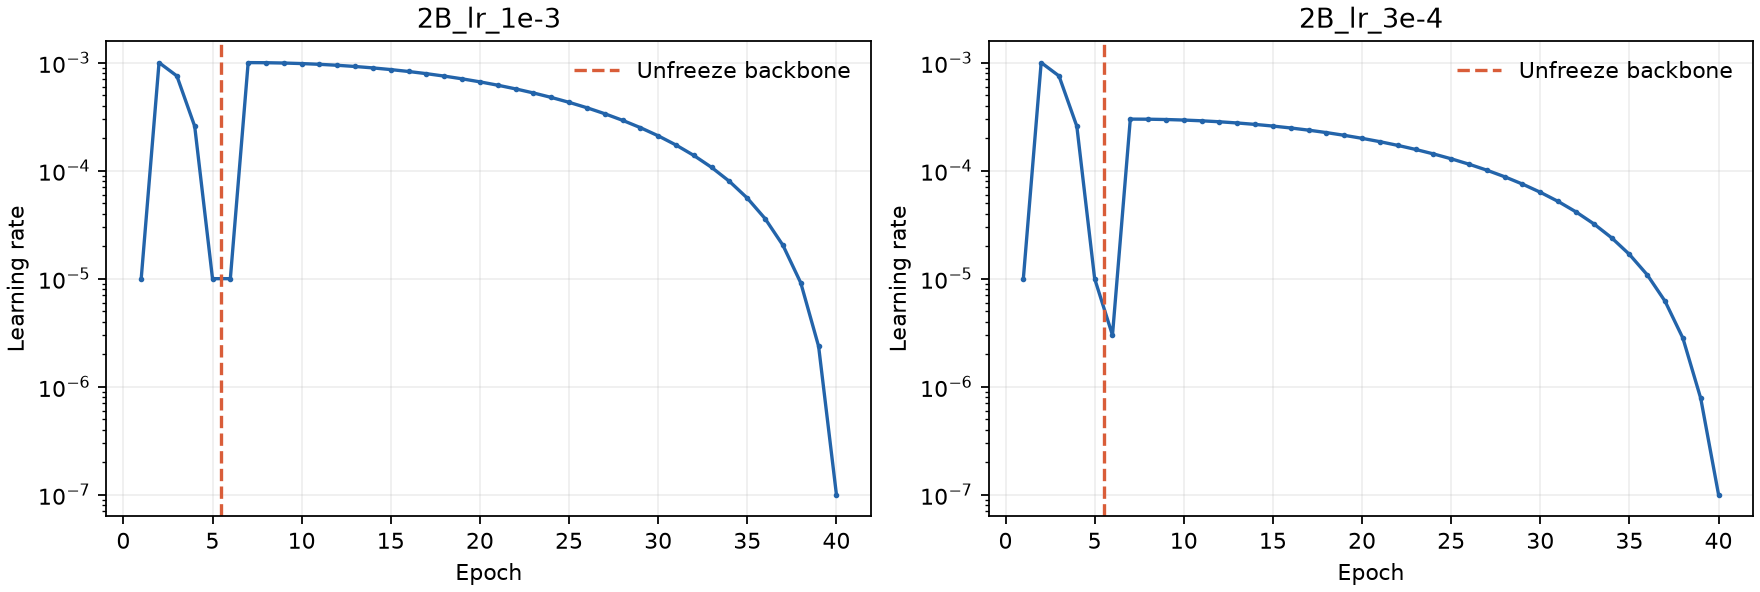

In [7]:
# Planned schedules, not measured accuracy curves.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), constrained_layout=True)
for axis, config in zip(axes, CANDIDATES):
    values = [learning_rate(config, epoch) for epoch in range(config.total_epochs)]
    axis.semilogy(range(1, config.total_epochs + 1), values, color="#2364AA", marker=".", markersize=3)
    axis.axvline(config.head_epochs + 0.5, color="#D95D39", linestyle="--", label="Unfreeze backbone")
    axis.set(xlabel="Epoch", ylabel="Learning rate", title=config.name)
    axis.grid(alpha=0.2)
    axis.legend(frameon=False)
fig.savefig(REPORT_DIR / "part2_learning_rates.png", dpi=160)
plt.close(fig)
display(Image(filename=str(REPORT_DIR / "part2_learning_rates.png")))

## Run Part 2A and Part 2B

This launches the 50-epoch baseline, two 40-epoch validation experiments, and
a final refit for the selected epoch count. Test evaluation happens only after
those choices are fixed. Preserve OUTPUT_DIR on persistent storage if needed.

In [8]:
RUN_FULL_TRAINING = False  # Set True to perform the full assignment experiment.
DATA_ROOT = Path("data")
OUTPUT_DIR = Path("runs/part2")

if RUN_FULL_TRAINING:
    summary = run_assignment(DATA_ROOT, OUTPUT_DIR)
else:
    print("Full training has not been run. Set RUN_FULL_TRAINING = True to start.")

Full training has not been run. Set RUN_FULL_TRAINING = True to start.


## New measured results

In [9]:
summary_path = OUTPUT_DIR / "summary.json"
if summary_path.exists():
    measured = json.loads(summary_path.read_text(encoding="utf-8"))
    lines = [
        "| Part | Test accuracy | Mean per-class accuracy | Epoch | Target >=70% |",
        "|---|---:|---:|---:|---|",
    ]
    for row in measured["results"]:
        lines.append(
            f"| {row['part']} | {100 * row['test_accuracy']:.2f}% | "
            f"{100 * row['test_macro_accuracy']:.2f}% | {row['epoch']} | "
            f"{row['target_70_percent_met']} |")
    display(Markdown("\n".join(lines)))
    print("Selected candidate:", measured["selected_candidate"])
    print(f"2B - 2A: {measured['improvement_percentage_points']:+.2f} percentage points")
    for plot_path in sorted(OUTPUT_DIR.glob("*/training.png")):
        display(Image(filename=str(plot_path)))
else:
    print("No new final test metrics exist yet.")
    print("Historical baseline: 84.31%; historical tuned claim: 87.13% (unverified).")

No new final test metrics exist yet.
Historical baseline: 84.31%; historical tuned claim: 87.13% (unverified).


## Reproduction and deliverables

Open Part2_ResNet18.ipynb in Colab or Jupyter. It embeds all training code and recorded baseline observations, so it can be uploaded alone. Set RUN_FULL_TRAINING = True in its run cell, select a GPU runtime if available, and run top to bottom. It uses torchvision to download the approximately 2.75 GB dataset and V1 weights if needed.

For a local command-line run:

~~~bash
python -m pip install -r requirements-part2.txt
python part2_resnet18.py --data-root data --output-dir runs/part2
~~~

Use a compatible CUDA build of PyTorch on a GPU machine. The installed local build is CPU-only. On Colab, its provided PyTorch installation can be used; installing the local CPU build there is unnecessary.

Each experiment's output folder contains last.pt, history.csv, training.png, and result.json; tuning runs also contain best.pt. Final models receive test metrics, predictions, and confusion matrices. The root contains environment/configuration metadata, class names, selection details, and the final comparison.

Rerunning with the same output directory resumes unfinished runs at epoch boundaries, including optimizer and random-number-generator state. Use the same library versions, device, dataset, and zero-worker loader for reproducible continuation. Preserve the output directory on persistent storage in an ephemeral runtime. Once a summary exists, rerunning displays its saved results instead of rerunning the test set. Use a new output directory for a deliberately new experiment.

The original notebook remains the provenance record. The new code corrects shared histories/checkpoints, unintended BatchNorm updates, test-based checkpoint selection, and inaccurate explanatory claims. It does not retrofit new scores into old outputs.